# DEAP: Evolutionary Algorithms

## Overview
DEAP (Distributed Evolutionary Algorithms in Python) provides:
- Genetic algorithms (GA)
- Particle swarm optimization (PSO)
- Differential evolution
- Multi-objective optimization (NSGA-II, SPEA2)
- Customizable operators and fitness functions

## Why DEAP for Engineering?
- Optimize complex, non-convex design spaces
- Handle multiple conflicting objectives
- No gradient information required

=== Single-Objective Optimization ===
Best solution: [-5.528333479661813e-09, 3.960050559901611e-09]
Best fitness: 0.000000


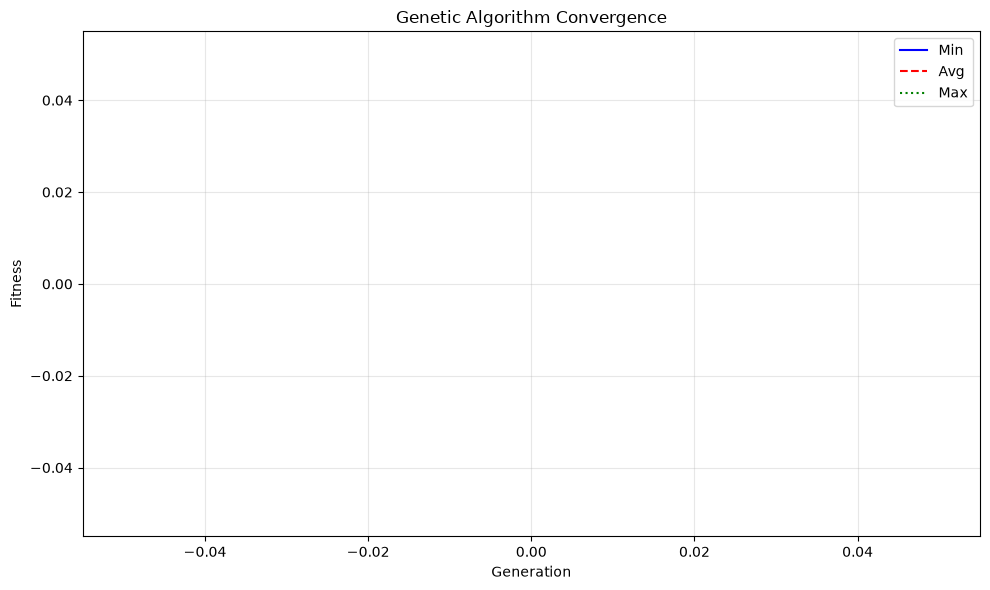

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from deap import base, creator, tools, algorithms
import random

# 1. Single-Objective Optimization
print("=== Single-Objective Optimization ===")

# Define the fitness function (minimize)
def sphere_function(x):
    """Sphere function: f(x) = sum(x_i^2)"""
    return sum(xi**2 for xi in x)

# Set up DEAP
creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
creator.create("Individual", list, fitness=creator.FitnessMin)

toolbox = base.Toolbox()
toolbox.register("attr_float", random.uniform, -5.0, 5.0)
toolbox.register("individual", tools.initRepeat, creator.Individual, 
                 toolbox.attr_float, n=2)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

def evaluate(individual):
    """Evaluate fitness - must return a tuple for DEAP"""
    return (sphere_function(individual),)

toolbox.register("evaluate", evaluate)
toolbox.register("mate", tools.cxBlend, alpha=0.5)
toolbox.register("mutate", tools.mutGaussian, mu=0, sigma=1.0, indpb=0.2)
toolbox.register("select", tools.selTournament, tournsize=3)

# Run the algorithm
pop = toolbox.population(n=100)
hof = tools.HallOfFame(1)
stats = tools.Statistics(lambda ind: ind.fitness.values[0])
stats.register("avg", np.mean)
stats.register("min", np.min)
stats.register("max", np.max)

pop, log = algorithms.eaSimple(pop, toolbox, cxpb=0.5, mutpb=0.2, 
                                ngen=50, stats=stats, halloffame=hof, verbose=False)

# Extract log data for plotting (DEAP 1.4: log is a Logbook, iterate over it directly)
log_records = {'min': [], 'avg': [], 'max': []}
for entry in log:
    if isinstance(entry, dict):
        for key in ['min', 'avg', 'max']:
            if key in entry:
                log_records[key].append(entry[key])

print(f"Best solution: {hof[0]}")
print(f"Best fitness: {hof[0].fitness.values[0]:.6f}")

# Plot convergence
plt.figure(figsize=(10, 6))
plt.plot(log_records['min'], 'b-', label='Min')
plt.plot(log_records['avg'], 'r--', label='Avg')
plt.plot(log_records['max'], 'g:', label='Max')
plt.xlabel('Generation')
plt.ylabel('Fitness')
plt.title('Genetic Algorithm Convergence')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Multi-Objective Optimization

Optimize multiple conflicting objectives simultaneously (e.g., minimize drag AND weight).

In [ ]:
# 2. Multi-Objective Optimization (NSGA-II)
print("\n=== Multi-Objective Optimization ===")

# Define two objectives
def objective1(x):
    """Minimize drag"""
    return (x[0] - 2)**2 + (x[1] - 1)**2

def objective2(x):
    """Minimize weight"""
    return (x[0] + 2)**2 + (x[1] + 1)**2

# Set up DEAP for multi-objective
creator.create("FitnessMin", base.Fitness, weights=(-1.0, -1.0))
creator.create("Individual", list, fitness=creator.FitnessMin)

toolbox = base.Toolbox()
toolbox.register("attr_float", random.uniform, -5.0, 5.0)
toolbox.register("individual", tools.initRepeat, creator.Individual, 
                 toolbox.attr_float, n=2)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

def evaluate_multiobj(individual):
    return (objective1(individual), objective2(individual))

toolbox.register("evaluate", evaluate_multiobj)
toolbox.register("mate", tools.cxBlend, alpha=0.5)
toolbox.register("mutate", tools.mutGaussian, mu=0, sigma=1.0, indpb=0.2)
toolbox.register("select", tools.selNSGA2)

# Run NSGA-II
pop = toolbox.population(n=100)
pop, log = algorithms.eaMuPlusLambda(pop, toolbox, mu=50, lambda_=50, 
                                      cxpb=0.5, mutpb=0.2, ngen=50, verbose=False)

# Extract Pareto front
pareto_front = tools.selNSGA2(pop, k=100)
obj1_vals = [ind.fitness.values[0] for ind in pareto_front]
obj2_vals = [ind.fitness.values[1] for ind in pareto_front]

# Plot Pareto front
plt.figure(figsize=(10, 6))
plt.scatter(obj1_vals, obj2_vals, c='blue', alpha=0.6, edgecolors='k')
plt.xlabel('Objective 1 (Drag)')
plt.ylabel('Objective 2 (Weight)')
plt.title('Pareto Front (NSGA-II)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Number of Pareto-optimal solutions: {len(pareto_front)}")

## Engineering Application: Airfoil Shape Optimization

Optimize airfoil parameters to minimize drag while maintaining lift.


=== Airfoil Shape Optimization ===
Optimal airfoil parameters:
Thickness: 0.080
Camber: 0.100
Camber position: 0.350
Minimum drag: 0.0195


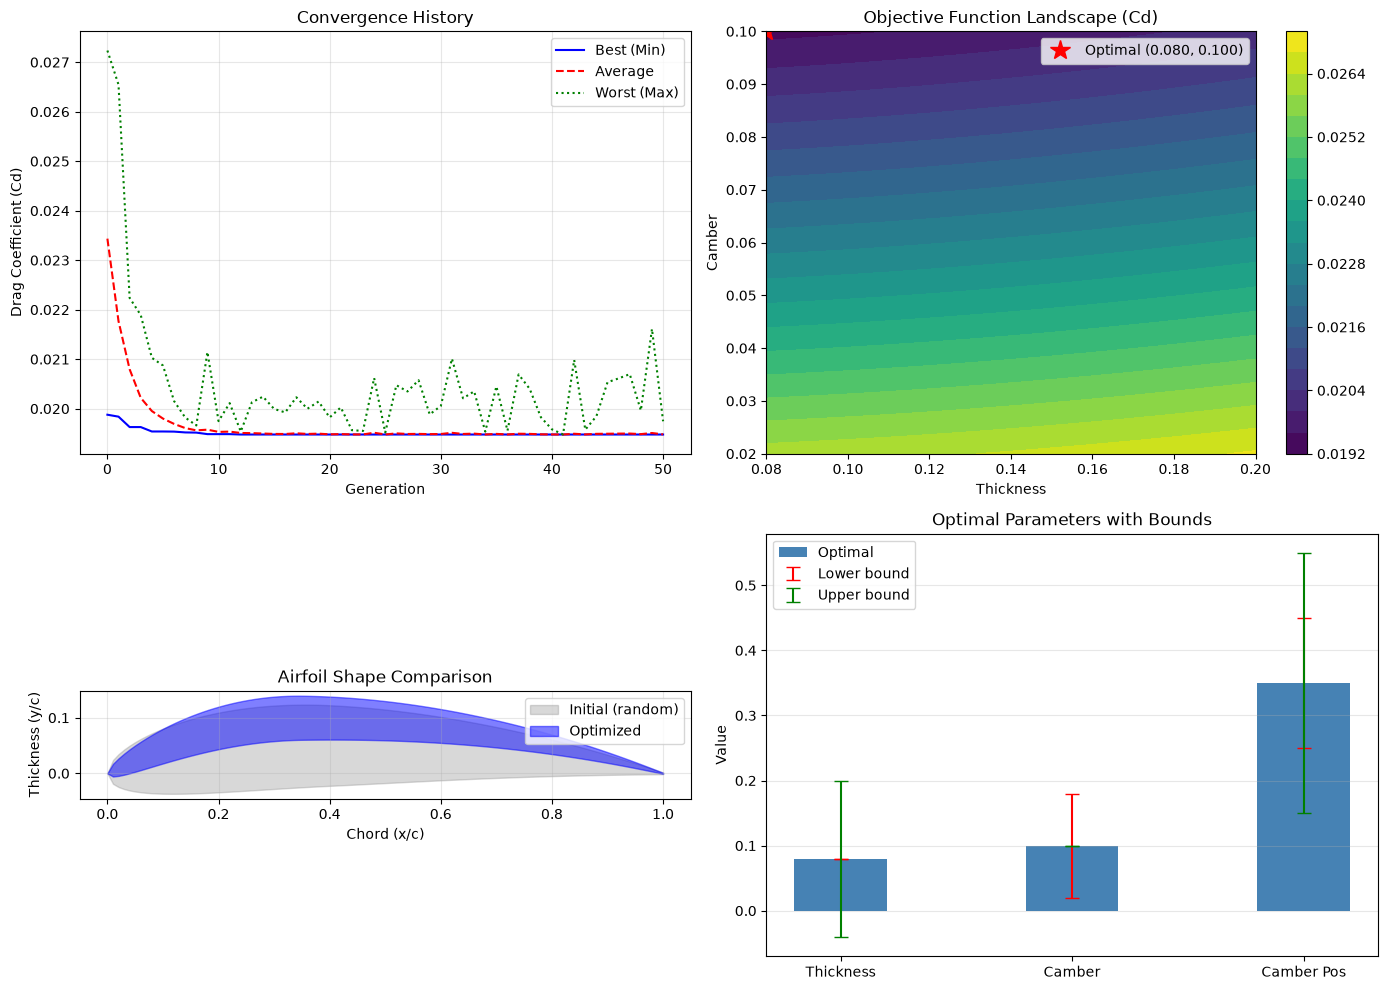

In [29]:
# 3. Engineering Application: Airfoil Optimization
print("\n=== Airfoil Shape Optimization ===")

# Define airfoil parameters
# x = [thickness, camber, camber_position]
def airfoil_objective(x):
    """
    Minimize drag while maintaining lift.
    x = [thickness, camber, camber_position]
    
    Realistic constraints:
    - thickness: 0.05 to 0.20 (5-20% of chord)
    - camber: 0.0 to 0.10 (0-10% of chord)
    - camber_position: 0.2 to 0.6 (20-60% of chord)
    """
    thickness, camber, camber_pos = x
    
    # More realistic drag model
    # Base drag + thickness penalty + camber penalty
    cd = 0.008 + 0.02 * thickness**2 + 0.01 * camber**2
    
    # Lift model (more realistic)
    # Lift depends on camber and camber position
    cl = 0.3 + 0.5 * camber - 0.2 * (camber_pos - 0.35)**2
    
    # Penalty if lift is too low (target cl >= 0.5)
    if cl < 0.5:
        cd += 0.5 * (0.5 - cl)**2
    
    # Penalty if thickness is too low (structural constraint)
    if thickness < 0.08:
        cd += 0.1 * (0.08 - thickness)**2
    
    return cd

# Set up DEAP (use unique names to avoid conflicts with previous examples)
creator.create("FitnessMinAirfoil", base.Fitness, weights=(-1.0,))
creator.create("IndividualAirfoil", list, fitness=creator.FitnessMinAirfoil)

toolbox = base.Toolbox()
toolbox.register("attr_float", random.uniform, 0.08, 0.20)  # thickness (min 8%)
toolbox.register("attr_camber", random.uniform, 0.02, 0.10)  # camber (min 2%)
toolbox.register("attr_pos", random.uniform, 0.25, 0.55)  # camber position

def individual():
    return creator.IndividualAirfoil([toolbox.attr_float(), toolbox.attr_camber(), toolbox.attr_pos()])

toolbox.register("individual", individual)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)
def evaluate_airfoil(individual):
    """Evaluate airfoil fitness - must return a tuple for DEAP"""
    return (airfoil_objective(individual),)

toolbox.register("evaluate", evaluate_airfoil)
toolbox.register("select", tools.selTournament, tournsize=3)

# Bounds for airfoil parameters
BOUNDS = [(0.08, 0.20), (0.02, 0.10), (0.25, 0.55)]

# Custom crossover that respects bounds
def bounded_crossover(ind1, ind2, alpha):
    """Blend crossover with bounds checking"""
    for i in range(len(ind1)):
        beta = random.random() * (1 + alpha) - alpha / 2
        child1 = ind1[i] + beta * (ind2[i] - ind1[i])
        child2 = ind2[i] - beta * (ind2[i] - ind1[i])
        # Clamp to bounds
        ind1[i] = max(BOUNDS[i][0], min(BOUNDS[i][1], child1))
        ind2[i] = max(BOUNDS[i][0], min(BOUNDS[i][1], child2))
    return (ind1, ind2)

# Custom mutation that respects bounds
def bounded_mutate(individual, mu, sigma, indpb):
    """Gaussian mutation with bounds checking"""
    for i, gene in enumerate(individual):
        if random.random() < indpb:
            gene += random.gauss(mu, sigma)
            # Clamp to bounds
            gene = max(BOUNDS[i][0], min(BOUNDS[i][1], gene))
            individual[i] = gene
    return (individual,)

toolbox.register("mate", bounded_crossover, alpha=0.5)
toolbox.register("mutate", bounded_mutate, mu=0, sigma=0.01, indpb=0.2)

# Run the algorithm and track best solution per generation
pop = toolbox.population(n=100)
hof = tools.HallOfFame(1)
stats = tools.Statistics(lambda ind: ind.fitness.values[0])
stats.register("avg", np.mean)
stats.register("min", np.min)
stats.register("max", np.max)

pop, log = algorithms.eaSimple(pop, toolbox, cxpb=0.5, mutpb=0.2, 
                                ngen=50, stats=stats, halloffame=hof, verbose=False)

best = hof[0]
print(f"Optimal airfoil parameters:")
print(f"Thickness: {best[0]:.3f}")
print(f"Camber: {best[1]:.3f}")
print(f"Camber position: {best[2]:.3f}")
print(f"Minimum drag: {best.fitness.values[0]:.4f}")

# Visualize the optimization process
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Convergence plot
ax1 = axes[0, 0]
log_records = {'min': [], 'avg': [], 'max': []}
for entry in log:
    if isinstance(entry, dict):
        for key in ['min', 'avg', 'max']:
            if key in entry:
                log_records[key].append(entry[key])
ax1.plot(log_records['min'], 'b-', label='Best (Min)')
ax1.plot(log_records['avg'], 'r--', label='Average')
ax1.plot(log_records['max'], 'g:', label='Worst (Max)')
ax1.set_xlabel('Generation')
ax1.set_ylabel('Drag Coefficient (Cd)')
ax1.set_title('Convergence History')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Parameter evolution (thickness vs camber)
ax2 = axes[0, 1]
thickness_history = []
camber_history = []
for entry in log:
    if isinstance(entry, dict) and 'min' in entry:
        # We don't have per-generation best individual, so we'll plot the final best
        pass
# Instead, let's create a 2D slice of the objective function
t_range = np.linspace(0.08, 0.20, 50)
c_range = np.linspace(0.02, 0.10, 50)
T, C = np.meshgrid(t_range, c_range)
CD = np.zeros_like(T)
for i in range(T.shape[0]):
    for j in range(T.shape[1]):
        CD[i, j] = airfoil_objective([T[i, j], C[i, j], 0.35])  # Fixed camber position
contour = ax2.contourf(T, C, CD, levels=20, cmap='viridis')
ax2.plot(best[0], best[1], 'r*', markersize=15, label=f'Optimal ({best[0]:.3f}, {best[1]:.3f})')
ax2.set_xlabel('Thickness')
ax2.set_ylabel('Camber')
ax2.set_title('Objective Function Landscape (Cd)')
ax2.legend()
plt.colorbar(contour, ax=ax2)

# 3. Airfoil shape comparison
ax3 = axes[1, 0]
def airfoil_shape(thickness, camber, camber_pos, n=100):
    """Generate airfoil coordinates"""
    x = np.linspace(0, 1, n)
    # Thickness distribution
    yt = 5 * thickness * (0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1015*x**4)
    # Camber line (vectorized)
    yc = np.where(x <= camber_pos,
                  camber / camber_pos**2 * (2*camber_pos*x - x**2),
                  camber / (1-camber_pos)**2 * ((1-2*camber_pos) + 2*camber_pos*x - x**2))
    # Upper and lower surfaces
    y_upper = yc + yt
    y_lower = yc - yt
    return x, y_upper, y_lower

# Plot initial random airfoil and optimal airfoil
x_init, yu_init, yl_init = airfoil_shape(0.15, 0.05, 0.4)
x_opt, yu_opt, yl_opt = airfoil_shape(best[0], best[1], best[2])
ax3.fill_between(x_init, yl_init, yu_init, alpha=0.3, color='gray', label='Initial (random)')
ax3.fill_between(x_opt, yl_opt, yu_opt, alpha=0.5, color='blue', label='Optimized')
ax3.set_xlabel('Chord (x/c)')
ax3.set_ylabel('Thickness (y/c)')
ax3.set_title('Airfoil Shape Comparison')
ax3.legend()
ax3.grid(True, alpha=0.3)
ax3.set_aspect('equal')

# 4. Parameter history (bar chart of final values)
ax4 = axes[1, 1]
params = ['Thickness', 'Camber', 'Camber Pos']
values = [best[0], best[1], best[2]]
bounds_min = [b[0] for b in BOUNDS]
bounds_max = [b[1] for b in BOUNDS]
x_pos = np.arange(len(params))
width = 0.4
bars = ax4.bar(x_pos, values, width, color='steelblue', label='Optimal')
ax4.errorbar(x_pos, values, yerr=[v-bm for v, bm in zip(values, bounds_min)], 
              fmt='none', color='red', capsize=5, label='Lower bound')
ax4.errorbar(x_pos, values, yerr=[bm-v for v, bm in zip(values, bounds_max)], 
              fmt='none', color='green', capsize=5, label='Upper bound')
ax4.set_xticks(x_pos)
ax4.set_xticklabels(params)
ax4.set_ylabel('Value')
ax4.set_title('Optimal Parameters with Bounds')
ax4.legend()
ax4.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## Exercises

1. Optimize a 5-dimensional function using a genetic algorithm.
2. Solve a bi-objective optimization problem and plot the Pareto front.
3. Compare GA vs PSO for the same problem.